# HVAC offline workbench

Read-only identification and counterfactual gain screening for Primary, Hailee and Main Floor.

Goal: reduce overshoot-driven hysteresis shutdowns and preserve effective recovery. A fitted model is not evidence of better gains. Review qualification before interpreting a candidate. No cell writes to a device or Home Assistant.

The aligned records are immutable research inputs. Prediction CSVs were generated chronologically without future temperature feedback. Source/config hashes and the actual time coverage are in `analysis.json`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
if os.environ.get('HVAC_SIM_RUN'):
    RUN = Path(os.environ['HVAC_SIM_RUN']).expanduser().resolve()
else:
    roots = [Path.cwd(), *Path.cwd().parents]
    TOOL = next((p / 'tools/simulation' for p in roots if (p / 'tools/simulation/runs').is_dir()), None)
    if TOOL is None:
        TOOL = next((p for p in roots if (p / 'hvacsim').is_dir()), None)
    if TOOL is None:
        raise RuntimeError('Open inside the repository or set HVAC_SIM_RUN to an analysis directory.')
    available = sorted((TOOL / 'runs').glob('*/analysis.json'), key=lambda p: p.stat().st_mtime)
    if not available:
        raise RuntimeError('Run hvac-sim analyze first, or set HVAC_SIM_RUN.')
    RUN = available[-1].parent
print('Inspecting:', RUN)
analysis = json.loads((RUN / 'analysis.json').read_text())
pd.DataFrame({name: {'qualified': r['qualification']['qualified'], 'reasons': ', '.join(r['qualification']['reasons']), 'command_changes': r['audit']['native_command_changes'], 'complete_days': len(r['audit']['splits']['complete_days'])} for name, r in analysis['rooms'].items()}).T

Inspecting: /Users/admin/projects/esphome-mitsubishiheatpump/tools/simulation/runs/2026-11-14


,qualified,reasons,command_changes,complete_days
primary,False,"does_not_beat_stronger_baseline_by_10_percent,...",1619,21
hailee,True,,2849,21
main,False,"does_not_beat_stronger_baseline_by_10_percent,...",840,21


## Held-out predictions

These are conditional response replays: recorded future commands, enablement, weather and fireplace state are supplied inputs. They are not operational forecasts from origin-known information. Persistence/trend baselines have less input information. Gain counterfactuals instead generate their own commands and enablement.

Inspect errors and the baselines. Intervals are empirical validation residual intervals, not guarantees for new controller policies. Look separately at heating, coasting, recovery, weather, fusion transitions and scheduled target changes.

In [2]:
path = RUN / 'predictions.csv'
predictions = pd.read_csv(path, parse_dates=['timestamp','origin']) if path.exists() else pd.DataFrame()
if not predictions.empty:
    display(predictions.groupby(['room','horizon_minutes']).agg(samples=('residual','size'), MAE=('residual', lambda x: abs(x).mean()), tail95=('residual', lambda x: abs(x).quantile(.95))))
else:
    print('No qualifying chronological data windows; inspect the audit.')

samples       MAE    tail95
room    horizon_minutes                             
hailee  5                     16  0.101907  0.271634
        15                    16  0.128051  0.320299
        30                    16  0.191135  0.439291
        60                    16  0.261869  0.617799
        150                   16  0.311688  0.821493
main    5                     16  0.066420  0.154139
        15                    16  0.171494  0.494130
        30                    16  0.213946  0.587716
        60                    16  0.253752  0.658610
        150                   16  0.321493  0.859194
primary 5                     16  0.091111  0.252215
        15                    16  0.190769  0.469254
        30                    16  0.284018  0.658162
        60                    16  0.211646  0.594573
        150                   16  0.243490  0.472203

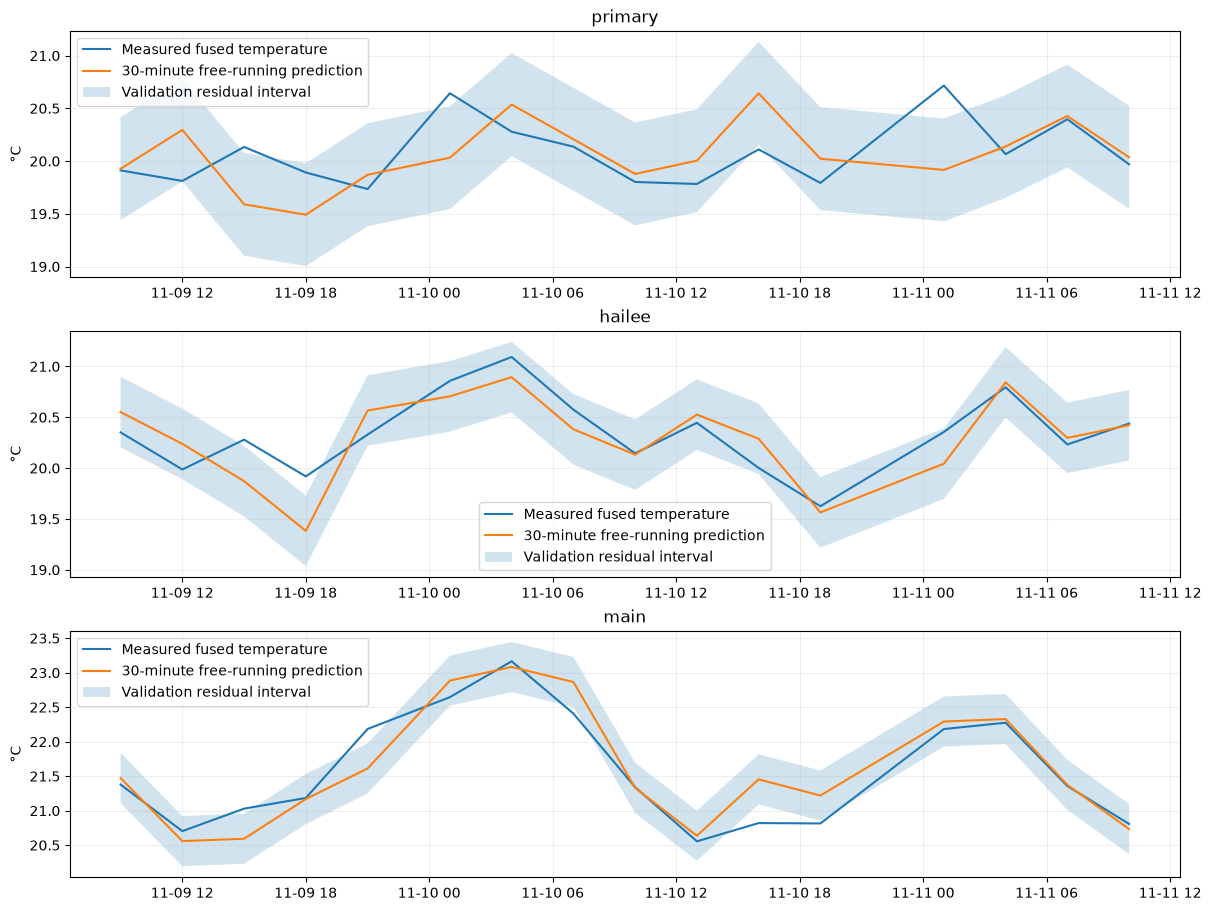

In [3]:
if not predictions.empty:
    fig, axes = plt.subplots(3,1,figsize=(12,9),constrained_layout=True)
    for ax, room in zip(axes, analysis['rooms']):
        x = predictions[(predictions.room == room) & (predictions.horizon_minutes == 30)]
        ax.plot(x.timestamp, x.observed, label='Measured fused temperature')
        ax.plot(x.timestamp, x.predicted, label='30-minute free-running prediction')
        half = analysis['rooms'][room].get('validation_intervals',{}).get('30')
        if half is not None:
            ax.fill_between(x.timestamp, x.predicted-half, x.predicted+half, alpha=.2, label='Validation residual interval')
        ax.set(title=room, ylabel='°C'); ax.legend(loc='best'); ax.grid(alpha=.2)
    plt.show()

## Command response and thermal momentum

A good temperature forecast does not establish a good input-response model. Compare command-change episodes against the constant-input ablation (enablement retained). Weak identification means we need informative bounded physical observations before ranking controller settings.

In [4]:
for room, result in analysis['rooms'].items():
    print(room, result['qualification'])
    display(pd.DataFrame(result.get('test',{}).get('command_response_episodes',[])))

primary {'qualified': False, 'reasons': ['does_not_beat_stronger_baseline_by_10_percent', 'fewer_than_three_held_out_command_change_episodes'], 'meaning': 'Screening eligibility only; does not authorize deployment or establish causal gain improvement.'}


""


hailee {'qualified': True, 'reasons': [], 'meaning': 'Screening eligibility only; does not authorize deployment or establish causal gain improvement.'}


,origin,steps,model_mae,constant_input_mae
0,2026-11-09 08:30:21.143719912+00:00,5,0.175551,0.285828
1,2026-11-09 11:30:21.143719912+00:00,2,0.235212,0.454895
2,2026-11-10 09:30:21.143719912+00:00,2,0.143240,0.319739
3,2026-11-10 12:30:21.143719912+00:00,2,0.164438,0.393537
4,2026-11-11 06:30:21.143719912+00:00,1,0.114595,0.095038
5,2026-11-11 09:30:21.143719912+00:00,3,0.182764,0.270748


main {'qualified': False, 'reasons': ['does_not_beat_stronger_baseline_by_10_percent', 'fewer_than_three_held_out_command_change_episodes'], 'meaning': 'Screening eligibility only; does not authorize deployment or establish causal gain improvement.'}


,origin,steps,model_mae,constant_input_mae
0,2026-11-09 14:30:21.143719912+00:00,2,0.251118,0.581631


## Gain experiments

Run the batch CLI to compare Kp/Ki/Kd across the retained model ensemble. Search uses training/validation scenarios, never final-test days. Unqualified models require an explicit `--exploratory` flag and every result stays labelled. Candidates are not approved for firmware deployment. Native operating activity and fusion weights must be generated by each counterfactual, not copied from future observations.

Compare shutdown counts, overshoot degree-minutes, recovery deficit, peak error, and command-trace equivalence. Other heads are fixed scenario context in this version; joint three-head gain optimization is not supported.

In [5]:
candidate_files = sorted(RUN.glob('*-search.json'))
for path in candidate_files:
    experiment = json.loads(path.read_text())
    print(path.name, experiment['notice'])
    display(pd.DataFrame([{'gains': c['gains'], 'passes_screen': c['passes_model_screen'], **c['worst']} for c in experiment['candidates']]))
if not candidate_files:
    print('No gain search run yet. Qualification/identification comes first.')

hailee-search.json No gain set is approved for deployment. Offline model-screen thresholds are engineering defaults, not comfort tolerances. Other heads are fixed scenario context. Independent online confirmation is required.


,gains,passes_screen,shutdowns,overshoot_degree_minutes,recovery_deficit_degree_minutes,absolute_degree_minutes,peak_overshoot,enabled_fraction,native_command_changes
0,"[0.58833, 9.941171, 0.0]",False,0.0,57.275716,0.0,59.207186,0.878254,0.470000,24.500000
1,"[191.356958, 3.60747, 0.025213]",False,0.0,57.826586,0.0,59.521956,0.875454,0.466667,46.333333
2,"[36.958487, 8.130696, 6.10528]",False,0.0,58.555676,0.0,60.249693,0.881271,0.465556,45.500000
3,"[205.637802, 0.903654, 18.401068]",False,0.0,58.585633,0.0,60.278355,0.876853,0.466667,45.666667
4,"[103.872436, 0.359768, 0.0]",False,0.0,61.305419,0.0,62.987994,0.889836,0.463333,46.166667
5,"[62.895651, 1.626144, 0.0]",False,0.0,63.812067,0.0,65.494641,0.903126,0.461111,45.333333
6,"[40.973978, 3.230651, 0.0]",False,0.0,65.701297,0.0,67.383772,0.917630,0.460000,43.333333
7,"[49.612264, 0.612919, 0.0]",False,0.0,67.433879,0.0,69.117240,0.928515,0.457778,44.000000
8,"[19.981177, 4.568476, 76.270783]",False,0.0,71.838843,0.0,73.521318,0.964080,0.455556,48.166667
9,"[29.962356, 0.79639, 49.561975]",False,0.0,74.024297,0.0,75.709484,0.982564,0.455556,44.000000
